# Black-box optimisation capstone: method and results

Imperial College Professional Certificate in Machine Learning and AI.

**The task.** Eight unknown functions (2 to 8 inputs, every input in [0, 1]). Each week I could submit **one** new input per function and see its output. The score is the **best value found** per function.

**What this notebook shows.**
1. The data: every query and result across 13 weeks.
2. The method: a Gaussian-process (GP) model plus an upper-confidence-bound (UCB) rule, with settings chosen by evidence.
3. A calibration check: is the model's uncertainty honest enough to trust?
4. Evidence of noise from repeated inputs.
5. TuRBO (a trust-region method), tested against real results.
6. Final results per function and per week.

**How to run.** From the repository root: `pip install -r requirements.txt`, then open this notebook. It takes about 3 to 5 minutes. All data is in `data/queries.csv`, and helper code is in `scripts/utils/`.

**Note on week 12.** The week-12 results email never arrived, so those eight queries have no recorded output (blank in the data). Everything else is complete.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root whether the notebook is opened from the root or from notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts" / "utils"))

import bbo_utils as bbo          # my helper functions (GP tuning, UCB, calibration, TuRBO)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
(ROOT / "results").mkdir(exist_ok=True)

## 1. The data

`data/queries.csv` has one row per observation: `function`, `week`, inputs `x1..x8` (unused inputs are blank), output `y`, and `source`.
Week 0 is the data supplied by the course. Weeks 1 to 13 are my weekly queries.

In [2]:
df = bbo.load_queries(ROOT / "data" / "queries.csv")

# Leaderboard places (40 places in total) reported to me by the course; F1 and F2 were not listed.
LEADERBOARD = {1: "not listed", 2: "not listed", 3: "3rd", 4: "34th", 5: "23rd", 6: "12th", 7: "7th", 8: "5th"}

rows = []
for f in range(1, 9):
    X, Y, W = bbo.get_xy(df, f)
    init = W == 0
    best_i = int(np.argmax(Y))
    rows.append(dict(function=f, inputs=bbo.DIMS[f], initial_points=int(init.sum()),
                     queries_submitted=int(((df.function == f) & (df.week >= 1)).sum()),
                     results_received=int((~init).sum()),
                     initial_best=Y[init].max(), final_best=Y.max(),
                     best_found_in_week=int(W[best_i])))
summary = pd.DataFrame(rows)
summary

,function,inputs,initial_points,queries_submitted,results_received,initial_best,final_best,best_found_in_week
0,1,2,10,13,12,7.710875e-16,1.380972e-08,7
1,2,2,10,13,12,6.112052e-01,6.112052e-01,0
2,3,3,15,13,12,-3.483531e-02,-7.266704e-04,8
3,4,4,30,13,12,-4.025542e+00,3.674588e-01,6
4,5,4,20,13,12,1.088860e+03,8.267229e+03,13
5,6,5,20,13,12,-7.142649e-01,-1.143800e-01,5
6,7,6,30,13,12,1.364968e+00,3.248264e+00,13
7,8,8,40,13,12,9.598482e+00,9.998325e+00,13


Reading the table: 13 queries were submitted per function, but only 12 results are known (week 12 is missing).
`best_found_in_week = 0` means my queries never beat the best point supplied with the course data (this is the case for F2).

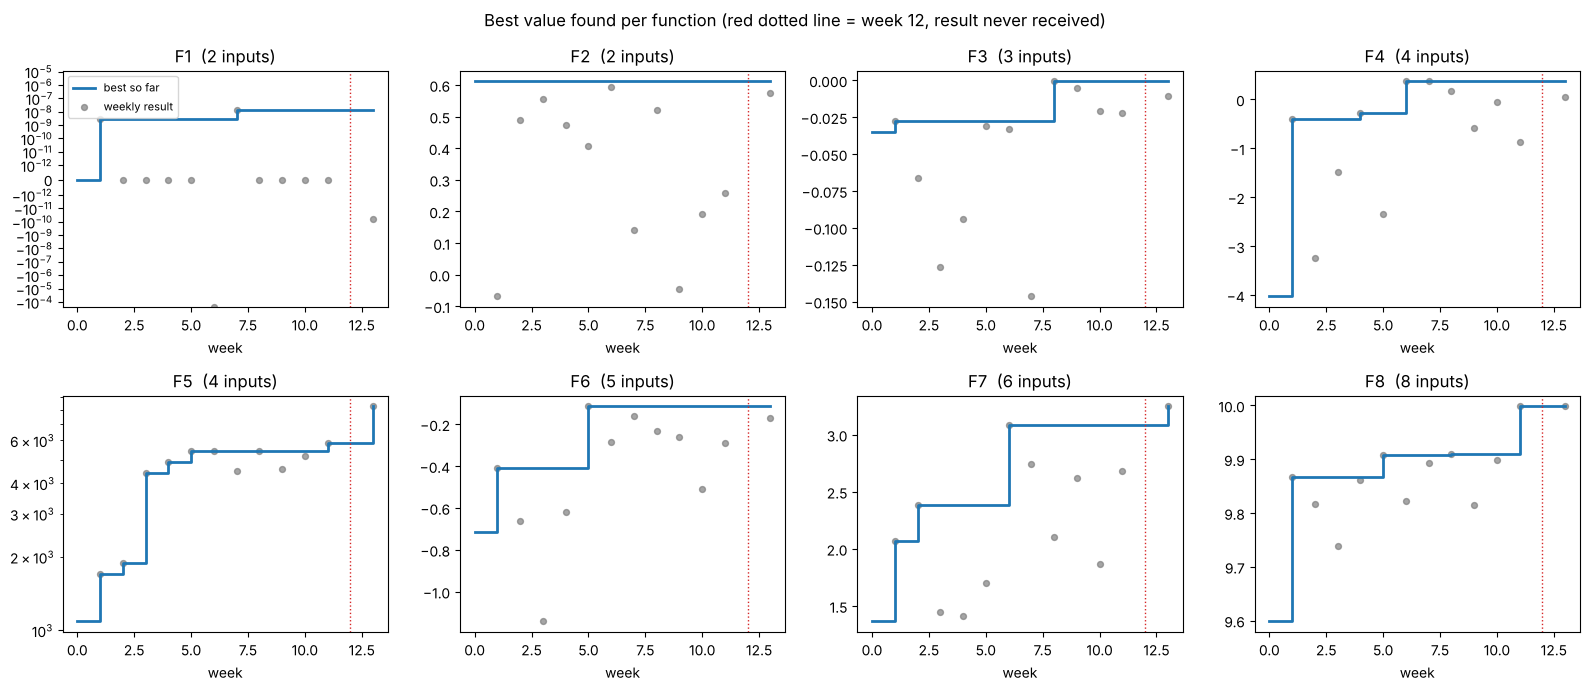

In [3]:
# Best value found so far, week by week. Dots are individual weekly results.
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for f, ax in zip(range(1, 9), axes.ravel()):
    X, Y, W = bbo.get_xy(df, f)
    weeks = np.arange(0, 14)
    # best-so-far per week: the best value among all observations up to that week
    line = [Y[W <= w].max() for w in weeks]
    ax.step(weeks, line, where="post", color="tab:blue", lw=2, label="best so far")
    ax.scatter(W[W >= 1], Y[W >= 1], s=18, color="tab:gray", alpha=0.7, label="weekly result")
    ax.axvline(12, color="tab:red", ls=":", lw=1)
    ax.set_title(f"F{f}  ({bbo.DIMS[f]} inputs)")
    ax.set_xlabel("week")
    if f == 1:
        ax.set_yscale("symlog", linthresh=1e-12)
    if f == 5:
        ax.set_yscale("log")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Best value found per function (red dotted line = week 12, result never received)")
fig.tight_layout()
fig.savefig(ROOT / "results" / "best_so_far.png", dpi=130)
plt.show()

## 2. Method: Gaussian process plus upper confidence bound

**Gaussian process (GP).** After every result, I fit a GP to all points seen so far. It predicts the output at any new input and also says how uncertain that prediction is.

**Upper confidence bound (UCB).** The next input is the one with the highest `mean + beta * uncertainty`. A large `beta` explores uncertain regions; a small `beta` exploits what looks good.

**Settings chosen by evidence, not defaults.** For each function I compared kernel type (RBF, Matern 1.5, Matern 2.5), the smallest allowed length-scale, and the assumed noise level (`alpha`). They are ranked by the *log marginal likelihood* (LML): higher means the model explains the data better without being needlessly complex.

**Why the length-scale bound matters.** On flat data (F1, F2) the fitted length-scale collapses toward zero, which gives a useless flat prediction. A lower bound limits the damage but does not cure it; the table below flags when a fit is still stuck at the bound.

In [4]:
# Pick the best (kernel, length-scale bound, alpha) per function using ALL results received.
# F5 is fitted on log(y) because its outputs span tens of thousands of times.
LOG_Y = {5: True}
best_cfg, tuning = {}, []
for f in range(1, 9):
    X, Y, W = bbo.get_xy(df, f)
    table = bbo.tune_gp(X, Y, log_y=LOG_Y.get(f, False))
    top = table.iloc[0]
    best_cfg[f] = top
    tuning.append(dict(function=f, n_points=len(Y), kernel=top.kernel, length_scale_bound=top.lower_bound,
                       alpha=top.alpha, fitted_length_scale=round(top.length_scale, 3),
                       stuck_at_bound=bool(top.pinned), lml=round(top.lml, 2),
                       log_transform=LOG_Y.get(f, False)))
pd.DataFrame(tuning)

,function,n_points,kernel,length_scale_bound,alpha,fitted_length_scale,stuck_at_bound,lml,log_transform
0,1,22,Matern_nu1.5,0.05,0.100000,0.050,True,-51.08,False
1,2,22,Matern_nu1.5,0.05,0.001000,0.071,False,-26.36,False
2,3,27,RBF,0.20,0.100000,0.240,False,-31.14,False
3,4,42,Matern_nu2.5,0.05,0.001000,0.773,False,-4.07,False
4,5,32,Matern_nu2.5,0.20,0.000001,0.575,False,-7.84,True
5,6,32,Matern_nu1.5,0.05,0.001000,0.923,False,-16.54,False
6,7,42,Matern_nu1.5,0.20,0.000001,0.675,False,-32.71,False
7,8,52,Matern_nu2.5,0.05,0.000001,1.678,False,-7.04,False


Several settings often have almost the same LML, so the top row can change between machines or after one more data point. I treat this table as "a reasonable choice", not "the one right answer".
F1 is stuck at its length-scale bound, and F2 sits close to it: the model has almost no signal to learn from there.

In [5]:
# What the weekly pipeline would propose from the final data (illustration only: the challenge has ended).
# For each function: UCB pick at beta = 1.0 (exploit) and beta = 1.96 (explore), with a duplicate check.
rows = []
for f in range(1, 9):
    X, Y, W = bbo.get_xy(df, f)
    cfg, log_y = best_cfg[f], LOG_Y.get(f, False)
    gp = bbo.fit_gp(X, Y, cfg.kernel, cfg.lower_bound, cfg.alpha, log_y, n_restarts=5)
    for beta in (1.0, 1.96):
        x, pred, std = bbo.ucb_pick(gp, bbo.DIMS[f], beta, log_y)
        rows.append(dict(function=f, beta=beta, proposal=np.round(x, 3).tolist(),
                         predicted=round(pred, 4), distance_to_nearest_prior=round(bbo.nearest_prior(X, x), 3),
                         duplicate=bbo.is_duplicate(X, x)))
pd.DataFrame(rows)

,function,beta,proposal,predicted,distance_to_nearest_prior,duplicate
0,1,1.00,"[0.51, 0.306]",-0.0001,0.084,False
1,1,1.96,"[0.49, 0.286]",-0.0001,0.110,False
2,2,1.00,"[0.694, 1.0]",0.5154,0.046,False
3,2,1.96,"[0.694, 1.0]",0.5154,0.046,False
4,3,1.00,"[0.248, 0.409, 0.516]",-0.0121,0.053,False
5,3,1.96,"[0.907, 0.996, 0.944]",-0.0732,0.405,False
6,4,1.00,"[0.385, 0.429, 0.41, 0.393]",0.1192,0.000,True
7,4,1.96,"[0.375, 0.324, 0.511, 0.401]",-0.6828,0.130,False
8,5,1.00,"[0.032, 0.021, 0.036, 0.992]",744.9028,0.685,False
9,5,1.96,"[0.032, 0.021, 0.036, 0.992]",744.9028,0.685,False


The `duplicate` flag marks a proposal within 0.02 of an earlier query. I added this check after F5 was submitted three times at nearly the same point and returned the identical value, so those queries taught me nothing.

Two things to notice in this table. First, the exploit setting (`beta = 1.0`) proposes an exact repeat of an earlier point for F4, F6 and F7: when the model's top choice is a point already queried, UCB simply asks for it again, which is why the duplicate check is needed. Second, F5's proposal sits far from every earlier point and predicts only about 745 against a best of 8,267. It is an exploration artefact of an unreliable model, and I did not use proposals like this in practice.

## 3. Can the model's uncertainty be trusted? (calibration check)

A GP always gives an uncertainty, but that does not mean it is right. For every weekly query I refit the model on **only the earlier data**, predicted that query, and measured the miss in units of the model's own uncertainty: `z = (actual - predicted) / predicted_std`.

If the uncertainty is honest, about 5% of misses should exceed 2 standard deviations. Much more than that means the model is overconfident, so I should only take small steps from it. I also read a very high learned noise level as "the model explains the data as noise".

In [6]:
calib, z_store = [], {}
for f in range(1, 9):
    X, Y, W = bbo.get_xy(df, f)
    res = bbo.forward_chaining_z(X, Y, W, log_y=LOG_Y.get(f, False))
    frac, mean_z, verdict = bbo.calibration_summary(res.z, noise=res.attrs["noise"])
    z_store[f] = res
    calib.append(dict(function=f, checks=len(res), share_outside_2sd=f"{frac:.0%}", mean_z=round(mean_z, 2),
                      learned_noise=round(res.attrs["noise"], 3), verdict=verdict))
pd.DataFrame(calib)

,function,checks,share_outside_2sd,mean_z,learned_noise,verdict
0,1,12,8%,1.54,0.952,not usable (model explains the data as noise)
1,2,12,17%,-0.28,0.106,borderline: use small steps only
2,3,12,25%,0.66,0.011,borderline: use small steps only
3,4,12,33%,0.05,0.003,poorly calibrated: do not trust model-guided j...
4,5,12,8%,0.83,0.000,acceptable: model-guided steps are reasonable
5,6,12,25%,-0.36,0.010,borderline: use small steps only
6,7,12,67%,0.61,0.000,poorly calibrated: do not trust model-guided j...
7,8,12,0%,-0.12,0.000,acceptable: model-guided steps are reasonable


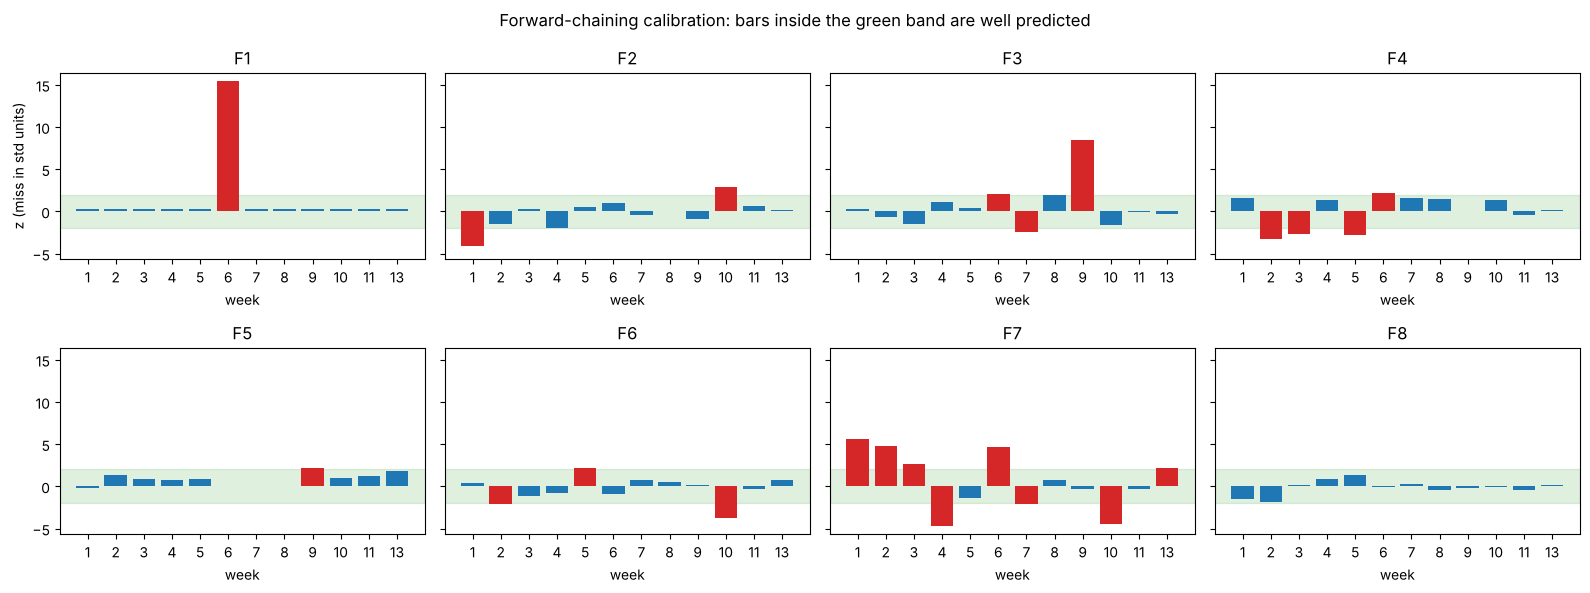

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
for f, ax in zip(range(1, 9), axes.ravel()):
    z = z_store[f]
    ax.axhspan(-2, 2, color="tab:green", alpha=0.15)
    ax.bar(z.week.astype(str), z.z, color=np.where(np.abs(z.z) > 2, "tab:red", "tab:blue"))
    ax.set_title(f"F{f}")
    ax.set_xlabel("week")
axes[0, 0].set_ylabel("z (miss in std units)")
fig.suptitle("Forward-chaining calibration: bars inside the green band are well predicted")
fig.tight_layout()
fig.savefig(ROOT / "results" / "calibration.png", dpi=130)
plt.show()

**How I used this.** F8 and F5 passed (few misses beyond 2 standard deviations), so I allowed model-guided jumps (TuRBO) there. F4 and F7 failed. F2, F3 and F6 were borderline, and F1 is explained as noise (learned noise 0.95). For those I stayed with small steps near known good points. This check decided how bold each function was allowed to be.

## 4. Noise: what repeated inputs reveal

If the same input returns different outputs, the function is noisy. Several inputs were submitted more than once by accident (or on purpose, for F6).

In [8]:
rep_rows = []
for f in range(1, 9):
    d = df[(df.function == f) & (df.week >= 1)].copy()
    xcols = [f"x{i+1}" for i in range(bbo.DIMS[f])]
    d["key"] = [tuple(np.round(r, 4)) for r in d[xcols].to_numpy(float)]   # identical inputs share a key
    for key, g in d.groupby("key"):
        if len(g) > 1:
            known = g.dropna(subset=["y"])
            rep_rows.append(dict(function=f, input=[float(v) for v in g.iloc[0][xcols]],
                                 weeks=g.week.tolist(), outputs=[float(v) for v in known.y.round(5)],
                                 identical_results=bool(known.y.nunique() == 1)))
rep = pd.DataFrame(rep_rows)
rep[rep.function.isin([4, 5, 6])]

,function,input,weeks,outputs,identical_results
0,4,"[0.3846, 0.429, 0.4098, 0.3929]","[6, 7]","[0.36746, 0.36746]",True
1,5,"[0.9228, 0.9866, 0.9849, 0.8955]","[5, 6, 8]","[5431.47235, 5431.47235, 5431.47235]",True
2,6,"[0.4402, 0.3901, 0.6726, 0.6905, 0.0459]","[5, 7, 12, 13]","[-0.11438, -0.16079, -0.16808]",False


F4 and F5 returned **exactly** the same value for the same input, so they look noise-free. F6 returned different values (about -0.114, -0.161 and -0.168), so F6 is noisy. That means my F6 best of -0.114 was most likely a lucky draw; its typical value at that input is nearer -0.15.
(F1 and F2 share one input in week 12 only because I submitted the same point to both; they are different functions.)

## 5. TuRBO (trust-region Bayesian optimisation) tested against real results

In 8 dimensions a global search spreads too thin. TuRBO searches only a box around the best point (box size grows after successes and halves after failures, with box sides set by how fast the function changes per input) and picks points by Thompson sampling.

Below is a *backtest*: use only the data available before a given week, ask TuRBO for its suggestion, and compare its prediction with the real result that came back.

In [9]:
bt = []
for f, upto, wk in ((8, 10, 11), (8, 11, 13), (5, 10, 11), (5, 11, 13)):
    X, Y, W = bbo.get_xy(df, f, last_week=upto)
    x_next, pred, (lo, hi), state, gp = bbo.turbo_suggestion(X, Y, W, log_y=LOG_Y.get(f, False))
    actual = float(df[(df.function == f) & (df.week == wk)].y.iloc[0])
    submitted = df[(df.function == f) & (df.week == wk)][[f"x{i+1}" for i in range(bbo.DIMS[f])]].to_numpy(float)[0]
    bt.append(dict(function=f, data_through_week=upto, target_week=wk, trust_region_length=state.length,
                   predicted=round(pred, 4), range_1sd=(round(lo, 4), round(hi, 4)), actual=round(actual, 4),
                   best_before=round(Y.max(), 4), is_new_best=actual > Y.max(),
                   same_as_submitted=bool(np.allclose(x_next, submitted, atol=0.02))))
pd.DataFrame(bt)

,function,data_through_week,target_week,trust_region_length,predicted,range_1sd,actual,best_before,is_new_best,same_as_submitted
0,8,10,11,0.8,10.0006,"(9.9949, 10.0063)",9.9981,9.9101,True,False
1,8,11,13,0.8,9.9980,"(9.9964, 9.9995)",9.9983,9.9981,True,True
2,5,10,11,0.8,5592.4639,"(5083.1822, 6152.7702)",5856.1017,5431.4723,True,False
3,5,11,13,0.8,6495.9264,"(6074.2712, 6946.8514)",8267.2293,5856.1017,True,True


**What this shows.**
- **F8:** the prediction landed inside its uncertainty range, and both runs gave a new best (9.9981 in week 11 and 9.9983 in week 13). For week 13 the TuRBO suggestion is the point I submitted. This is the case where the calibration check paid off.
- **F5:** week 11 was also a new best, close to the prediction. In week 13 I did **not** submit the TuRBO point; I submitted the boundary corner `[1, 1, 0.9787, 1]` (the GP's own peak), and it returned 8,267, well above the TuRBO prediction of about 6,500. The model under-estimated the boundary: all four inputs near their upper limit was better than a smooth trust-region model expected.

## 6. Final results

Best value found per function, with the input that produced it.

In [10]:
final = []
for f in range(1, 9):
    X, Y, W = bbo.get_xy(df, f)
    i = int(np.argmax(Y))
    init_best = Y[W == 0].max()
    final.append(dict(function=f, inputs=bbo.DIMS[f], initial_best=init_best, final_best=Y[i],
                      found_in_week=int(W[i]), best_input=np.round(X[i], 4).tolist(),
                      leaderboard=LEADERBOARD[f]))
final = pd.DataFrame(final)
pd.options.display.float_format = "{:.6g}".format
final

,function,inputs,initial_best,final_best,found_in_week,best_input,leaderboard
0,1,2,7.71088e-16,1.38097e-08,7,"[0.6939, 0.7143]",not listed
1,2,2,0.611205,0.611205,0,"[0.7026, 0.9266]",not listed
2,3,3,-0.0348353,-0.00072667,8,"[0.4098, 0.5249, 0.4771]",3rd
3,4,4,-4.02554,0.367459,6,"[0.3846, 0.429, 0.4098, 0.3929]",34th
4,5,4,1088.86,8267.23,13,"[1.0, 1.0, 0.9787, 1.0]",23rd
5,6,5,-0.714265,-0.11438,5,"[0.4402, 0.3901, 0.6726, 0.6905, 0.0459]",12th
6,7,6,1.36497,3.24826,13,"[0.2159, 0.1817, 0.4316, 0.2663, 0.2863, 0.6392]",7th
7,8,8,9.59848,9.99833,13,"[0.1118, 0.1486, 0.1223, 0.1653, 0.7849, 0.494...",5th


In [11]:
# Week-by-week outputs (blank = week 12, result never received). Also saved to results/results_per_week.csv.
weekly = df[df.week >= 1].pivot(index="week", columns="function", values="y")
weekly.columns = [f"F{c}" for c in weekly.columns]
init_row = pd.DataFrame({f"F{f}": [df[(df.function == f) & (df.week == 0)].y.max()] for f in range(1, 9)}, index=["initial best"])
out = pd.concat([init_row, weekly])
out.index.name = "week"
out.to_csv(ROOT / "results" / "results_per_week.csv")
out

,F1,F2,F3,F4,F5,F6,F7,F8
week,,,,,,,,
initial best,7.71088e-16,0.611205,-0.0348353,-4.02554,1088.86,-0.714265,1.36497,9.59848
1,2.67529e-09,-0.0691302,-0.0272537,-0.393294,1703.15,-0.410364,2.06794,9.86742
2,3.77596e-34,0.490036,-0.0665392,-3.23141,1880.19,-0.664418,2.38482,9.81698
3,5.70619e-35,0.555603,-0.126617,-1.47326,4397.23,-1.14186,1.44315,9.73924
4,0,0.472754,-0.0941046,-0.276567,4890.54,-0.620317,1.41058,9.86196
5,5.54727e-124,0.407872,-0.0312323,-2.3371,5431.47,-0.11438,1.7026,9.9078
6,-0.000232134,0.592525,-0.0330079,0.367459,5431.47,-0.285967,3.08285,9.82234
7,1.38097e-08,0.140681,-0.146505,0.367459,4486.78,-0.160786,2.73914,9.89274
8,1.51418e-192,0.522145,-0.00072667,0.166858,5431.47,-0.230942,2.10365,9.91007


## 7. Reading the results honestly

- **Where the model was trustworthy (F8, and F5 after a log transform), model-guided steps worked best.** F8 reached 9.99833 and F5 reached 8,267. F7 improved late with small steps (3.248).
- **F4 and F6 are fragile.** F4 is rough (nearby points can differ by more than 1), so its best (0.368) may be a lucky spot. F6 is noisy, so -0.114 is probably lucky.
- **F1 and F2 gained little.** The model had almost no signal (F1) or never beat the starting data (F2).
- **F5's boundary corner beat the model's prediction.** Next time I would test boundary corners earlier on functions where the best points sit against an input limit.
- **Limits.** Leaderboard places are as reported to me and may predate the last results. Week-12 outputs are missing. Hyperparameter rankings are close, so exact settings may differ between machines.

See `docs/model_card.md` and `docs/datasheet.md` for the model's limits and the data's context.